In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import IPython.display as ipd

# Point to single_stroke_synthesis/src
sys.path.append(os.path.abspath(os.path.join('..', 'src')))
from modal import ModalSynthesizer

sr = 44100
synth = ModalSynthesizer(sr=sr)
print("Modal Synthesis Engine Loaded.")

Modal Synthesis Engine Loaded.


In [144]:
# ==============================================================================
# CELL 2: Parameterizing the Stroke (10-Mode Pure Data Extraction)
# ==============================================================================

modes = [
    {'freq': 70.0,   'q': 2.2,  'amp': 2.60},
    {'freq': 130.0,   'q': 1.0,  'amp': 0.10},
    {'freq': 170.0,   'q': 1.0,  'amp': 0.20},
    {'freq': 220.0,  'q': 3.0,  'amp': 0.20},
    {'freq': 290.7,  'q': 7.6,  'amp': 2.75},
    {'freq': 330.0,  'q': 7.7, 'amp': 0.10},
    {'freq': 340.0,  'q': 7.7, 'amp': 0.10},
    {'freq': 360.0,  'q': 7.7, 'amp': 0.10},
    {'freq': 380.0,  'q': 7.7, 'amp': 0.10},
    {'freq': 440.3,  'q': 17, 'amp': 0.70},
    {'freq': 510.3,  'q': 10.0, 'amp': 0.10},
    {'freq': 592.2,  'q': 28.5, 'amp': 0.35},
    {'freq': 650.2,  'q': 20.0, 'amp': 0.50},
    {'freq': 700.2,  'q': 20.0, 'amp': 0.10},
    {'freq': 742.9,  'q': 39.2, 'amp': 0.50},
    {'freq': 810.9,  'q': 39.2, 'amp': 0.50},
    {'freq': 880.9,  'q': 39.2, 'amp': 0.50},
]

exciter_params = {
    'attack_ms': 1.5,
    'decay_ms': 25.0,
    'noise_fc': 301.0, 
    'noise_color': 'pink' 
}

In [145]:
audio_out = synth.synthesize(
    modes=modes, 
    duration=1.5, 
    attack_ms=exciter_params['attack_ms'], 
    decay_ms=exciter_params['decay_ms'],
    noise_fc=350.0,      # Pushes the static noise into a warm, mid-low "thwack"
    noise_q=1.0,         # Wide bandwidth for the slap
    q_multiplier=15.0,    # Forces the math to ring acoustically
)

print("Synthesized 'hit_low' Stroke (Filtered Exciter + Boosted Q):")
display(ipd.Audio(audio_out, rate=sr))

Synthesized 'hit_low' Stroke (Filtered Exciter + Boosted Q):


/tmp/ipykernel_95647/506943791.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


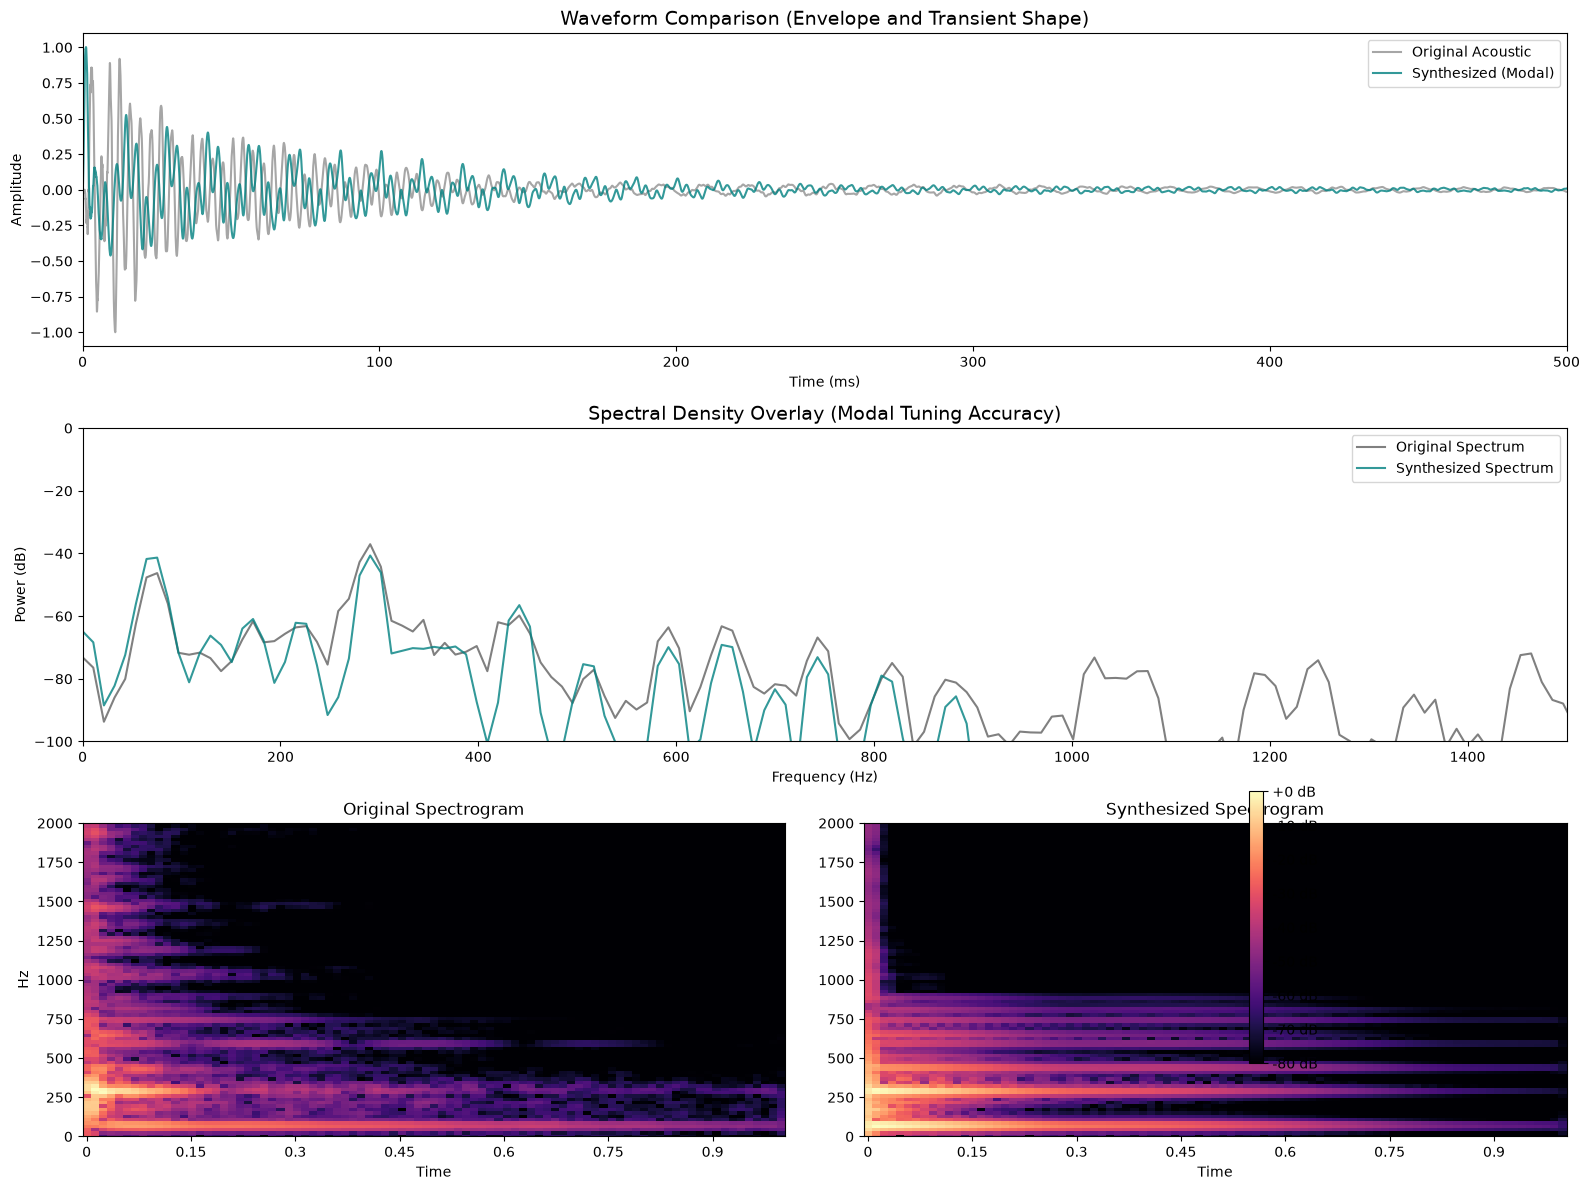

In [146]:
# ==============================================================================
# CELL 4: Visual/Acoustic Comparison (Original vs. Synthesized)
# ==============================================================================
import librosa
import librosa.display
import scipy.signal as signal

# 1. Load the original reference audio
# UPDATE THIS PATH to your actual segmented hit_low .wav file
original_file_path = '../../single_stroke_analysis/data/raw/hit_low/GIO_MEE_tombak_hit_low.wav' 
original_audio, _ = librosa.load(original_file_path, sr=sr)

# Normalize both signals for a fair visual comparison
original_audio = original_audio / np.max(np.abs(original_audio))
synth_audio = audio_out / np.max(np.abs(audio_out))

# Trim or pad to the same length (e.g., 1.0 seconds)
compare_length = int(sr * 1.0)
orig_trimmed = original_audio[:compare_length] if len(original_audio) > compare_length else np.pad(original_audio, (0, compare_length - len(original_audio)))
synth_trimmed = synth_audio[:compare_length] if len(synth_audio) > compare_length else np.pad(synth_audio, (0, compare_length - len(synth_audio)))

time_axis = np.arange(compare_length) / sr * 1000  # in milliseconds

# 2. Create the Figure
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(3, 2)

# --- PLOT 1: Waveforms (Time Domain) ---
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(time_axis, orig_trimmed, label='Original Acoustic', color='gray', alpha=0.7)
ax1.plot(time_axis, synth_trimmed, label='Synthesized (Modal)', color='teal', alpha=0.8)
ax1.set_title("Waveform Comparison (Envelope and Transient Shape)", fontsize=14)
ax1.set_ylabel("Amplitude")
ax1.set_xlabel("Time (ms)")
ax1.set_xlim(0, 500) # Zoom into the first 500ms
ax1.legend(loc='upper right')

# --- PLOT 2: Power Spectral Density (Frequency Domain) ---
ax2 = fig.add_subplot(gs[1, :])
f_orig, Pxx_orig = signal.welch(orig_trimmed, sr, nperseg=4096)
f_synth, Pxx_synth = signal.welch(synth_trimmed, sr, nperseg=4096)

ax2.plot(f_orig, 10 * np.log10(Pxx_orig), label='Original Spectrum', color='gray')
ax2.plot(f_synth, 10 * np.log10(Pxx_synth), label='Synthesized Spectrum', color='teal', alpha=0.8)
ax2.set_title("Spectral Density Overlay (Modal Tuning Accuracy)", fontsize=14)
ax2.set_ylabel("Power (dB)")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_xlim(0, 1500) # Focus on the main modal region
ax2.set_ylim(-100, 0)
ax2.legend(loc='upper right')

# --- PLOT 3 & 4: Spectrograms (Time-Frequency Domain) ---
ax3 = fig.add_subplot(gs[2, 0])
S_orig = librosa.amplitude_to_db(np.abs(librosa.stft(orig_trimmed, n_fft=2048, hop_length=512)), ref=np.max)
librosa.display.specshow(S_orig, sr=sr, x_axis='time', y_axis='hz', ax=ax3, cmap='magma', vmin=-80, vmax=0)
ax3.set_title("Original Spectrogram")
ax3.set_ylim(0, 2000)

ax4 = fig.add_subplot(gs[2, 1])
S_synth = librosa.amplitude_to_db(np.abs(librosa.stft(synth_trimmed, n_fft=2048, hop_length=512)), ref=np.max)
img = librosa.display.specshow(S_synth, sr=sr, x_axis='time', y_axis='hz', ax=ax4, cmap='magma', vmin=-80, vmax=0)
ax4.set_title("Synthesized Spectrogram")
ax4.set_ylim(0, 2000)
ax4.set_ylabel("") # Hide Y label for the second spectrogram

# Add a shared colorbar for the spectrograms
fig.colorbar(img, ax=[ax3, ax4], format="%+2.0f dB", pad=0.01)

plt.tight_layout()
plt.show()